In [1]:
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

In [2]:
births = Table.read_table('data/baby.csv')
births

Birth Weight,Gestational Days,Maternal Age,Maternal Height,Maternal Pregnancy Weight,Maternal Smoker
120,284,27,62,100,False
113,282,33,64,135,False
128,279,28,64,115,True
108,282,23,67,125,True
136,286,25,62,93,False
138,244,33,62,178,False
132,245,23,65,140,False
120,289,25,62,125,False
143,299,30,66,136,True
140,351,27,68,120,False


In [3]:
smoking_and_birth_weight = births.select('Maternal Smoker', 'Birth Weight')
smoking_and_birth_weight

Maternal Smoker,Birth Weight
False,120
False,113
True,128
True,108
False,136
False,138
False,132
False,120
True,143
False,140


In [ ]:
# Crushed ICE:
# 1. get the # of babies born to mothers who smoked & mothers who did not smoke
# 2. get the avg. birth weights of each group

In [5]:
smoking_and_birth_weight.group('Maternal Smoker')

Maternal Smoker,count
False,715
True,459


In [6]:
smoking_and_birth_weight.group('Maternal Smoker', np.average)

Maternal Smoker,Birth Weight average
False,123.085
True,113.819


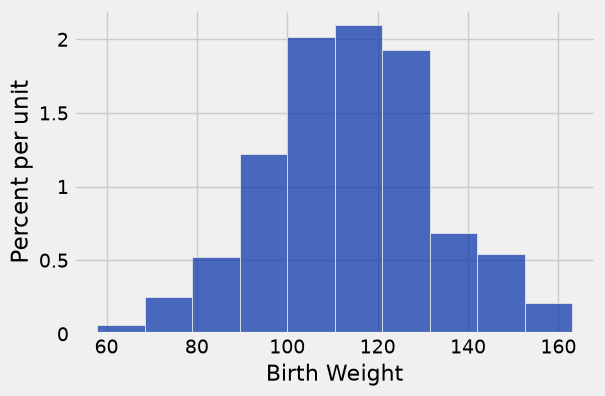

In [8]:
smoking_and_birth_weight.where('Maternal Smoker', True).hist('Birth Weight')

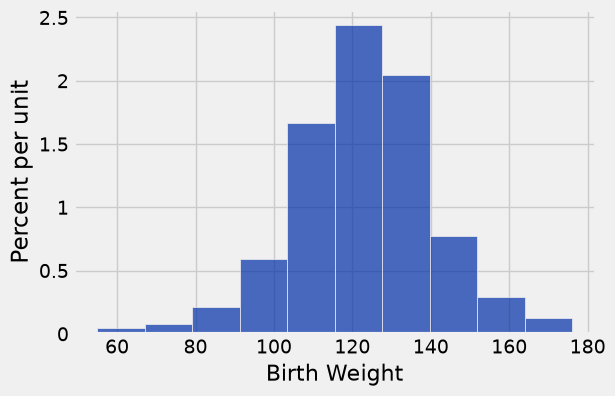

In [9]:
smoking_and_birth_weight.where('Maternal Smoker', False).hist('Birth Weight')

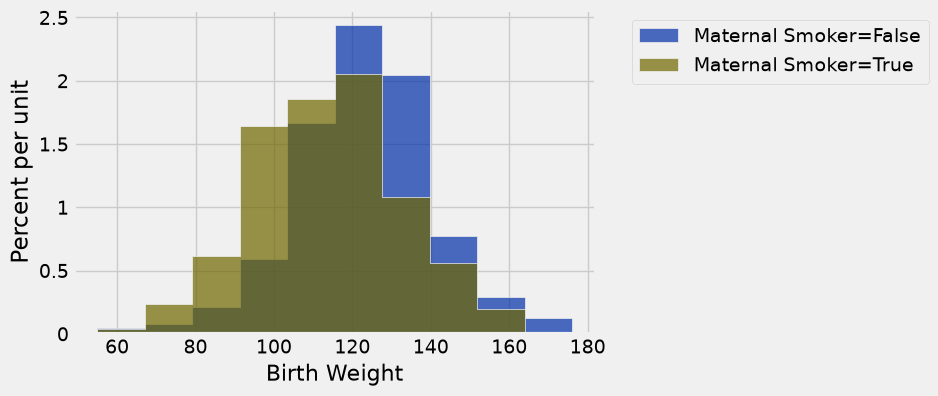

In [10]:
smoking_and_birth_weight.hist('Birth Weight', group='Maternal Smoker')

In [12]:
means_table = smoking_and_birth_weight.group('Maternal Smoker', np.average)
means_table

Maternal Smoker,Birth Weight average
False,123.085
True,113.819


In [13]:
means = means_table.column(1)
observed_difference = means.item(1) - means.item(0)
observed_difference

-9.266142572024918

In [15]:
smoking_and_birth_weight

Maternal Smoker,Birth Weight
False,120
False,113
True,128
True,108
False,136
False,138
False,132
False,120
True,143
False,140


In [16]:
smoking_and_birth_weight.sample(smoking_and_birth_weight.num_rows, with_replacement=False)

Maternal Smoker,Birth Weight
True,101
False,91
True,102
True,99
True,117
False,129
False,127
True,109
False,135
False,128


In [23]:
shuffled_labels = smoking_and_birth_weight.sample(smoking_and_birth_weight.num_rows, with_replacement=False).column(0)
original_and_shuffled = smoking_and_birth_weight.with_column('Shuffled Label', shuffled_labels)
original_and_shuffled

Maternal Smoker,Birth Weight,Shuffled Label
False,120,True
False,113,True
True,128,True
True,108,False
False,136,True
False,138,False
False,132,True
False,120,False
True,143,False
False,140,True


In [27]:
shuffled_only = original_and_shuffled.select('Birth Weight', 'Shuffled Label')
shuffled_group_means = shuffled_only.group('Shuffled Label', np.average)
shuffled_group_means

Shuffled Label,Birth Weight average
False,119.62
True,119.218


In [28]:
means = shuffled_group_means.column(1)
sample_difference = means.item(1) - means.item(0)
sample_difference

-0.4017154958331446

In [29]:
def difference_of_means(table, group_label):
    reduced = table.select('Birth Weight', group_label)
    group_means = reduced.group(group_label, np.average)
    means = group_means.column(1)
    difference = means.item(1) - means.item(0)
    return difference

In [31]:
difference_of_means(original_and_shuffled, 'Maternal Smoker')

-9.266142572024918

In [32]:
difference_of_means(original_and_shuffled, 'Shuffled Label')

-0.4017154958331446

In [33]:
def one_simulated_difference_of_means():
    # make an array of shuffled labels
    shuffled_labels = smoking_and_birth_weight.sample(smoking_and_birth_weight.num_rows, with_replacement=False).column(0)

    # attach to the birth weights of the original table
    original_and_shuffled = smoking_and_birth_weight.with_column('Shuffled Label', shuffled_labels)

    # calculate difference of means using shuffled labels
    return difference_of_means(original_and_shuffled, 'Shuffled Label')

In [39]:
one_simulated_difference_of_means()

-0.20854396148513388

In [40]:
# Crushed ICE: run one_simulated_difference_of_means 5000 times and save each simulated
# difference in an array called differences

In [41]:
differences = make_array()

repetitions = 5000
for i in np.arange(repetitions):
    differences = np.append(differences, one_simulated_difference_of_means())

differences

array([-1.51781769,  0.89682649, -1.39619117, ..., -0.19065771,
       -0.48399226, -0.62350504])

In [42]:
# Crushed ICE: generate a histogram of these differences and compare it to our
# observed_difference
# Generate a p-value too!

Observed Difference: -9.266142572024918


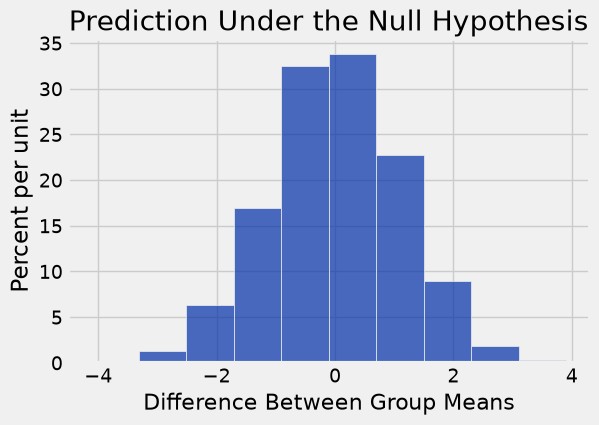

In [43]:
Table().with_column('Difference Between Group Means', differences).hist()
plt.title('Prediction Under the Null Hypothesis')
print('Observed Difference:', observed_difference)

In [44]:
empirical_p = np.count_nonzero(differences <= observed_difference) / repetitions
empirical_p

0.0

In [ ]:
# Conclusion: we reject the null hypothesis

---

# Super Soda

In [6]:
sample_proportions(200, [0.5, 0.5])

array([ 0.485,  0.515])

In [14]:
np.count_nonzero(np.random.choice(make_array('H', 'T'), 200) == 'H')

97

In [17]:
def simulate_one_count(sample_size):
    return np.count_nonzero(np.random.choice(make_array('H', 'T'), sample_size) == 'H')

simulate_one_count(200)

95

In [18]:
num_simulations = 10000
counts = make_array()

for i in np.arange(num_simulations):
    counts = np.append(counts, simulate_one_count(200))

counts

array([ 101.,   96.,  106., ...,   92.,   97.,  101.])

Text(0.5, 1.0, 'Prediction Under the Null')

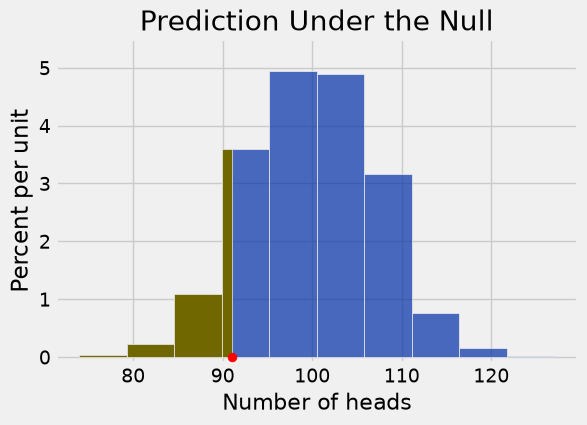

In [20]:
trials = Table().with_column('Number of heads', counts)
trials.hist(right_end=91)
plt.ylim(-0.001, 0.055)
plt.scatter(91, 0, color='red', s=40, zorder=3)
plt.title('Prediction Under the Null')

In [23]:
np.count_nonzero(counts <= 91) / len(counts)

0.1149

In [ ]:
# Conclusion: we do not reject the null hypothesis
# If you were the manufacturer, you'd probably try a bigger sample to confirm 
# that it was just random chance!

## Changing the number of simulations

In [49]:
# Keeping the data fixed, we can re-run the test with a new simulation under the null
def run_test(num_simulations, sample_size):
    counts = make_array()
    for i in np.arange(num_simulations):
        counts = np.append(counts, simulate_one_count(sample_size))
    return counts

counts = run_test(10000, 200)
np.count_nonzero(counts <= 91)/len(counts)

0.1167

In [50]:
# Let's repeat that 50 times for each number of simulations
tests = Table(['simulations', 'p-value for 91'])
for num_sims in [100, 1000, 10000]:
    for k in np.arange(50):
        counts = run_test(num_sims, 200)
        tests = tests.with_row([
            num_sims, 
            np.count_nonzero(counts <= 91)/len(counts),
        ])
tests.sample(10)

simulations,p-value for 91
1000,0.11
100,0.09
100,0.13
100,0.05
10000,0.1193
1000,0.109
10000,0.1162
10000,0.1157
1000,0.12
100,0.11


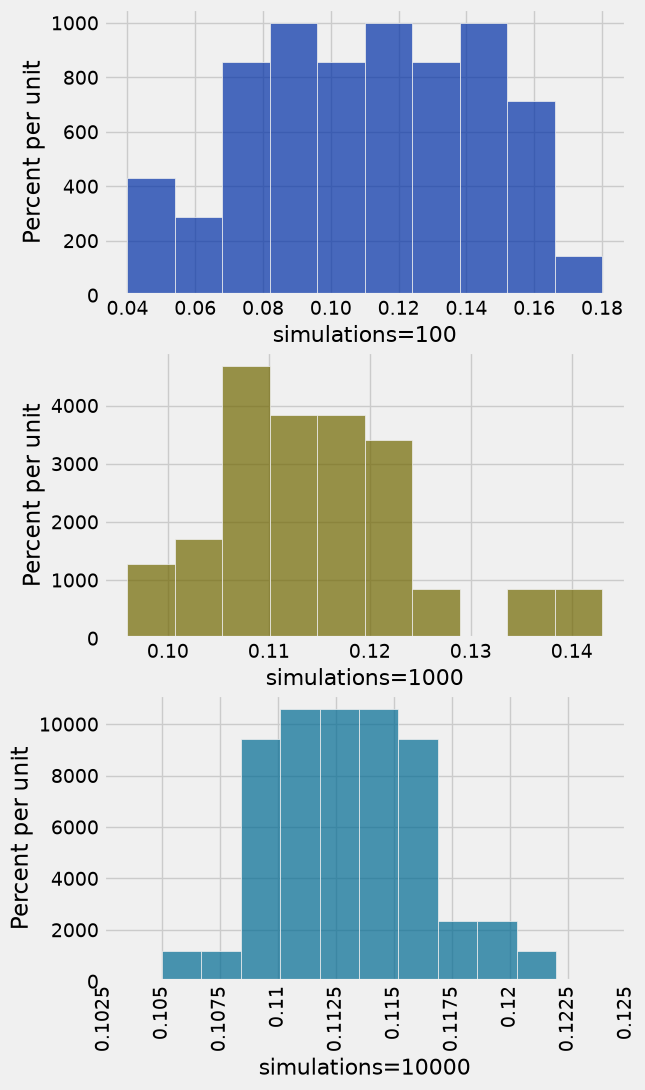

In [51]:
# For larger numbers of simulations, p-values are more consistent
tests.hist(1, group='simulations', overlay=False)

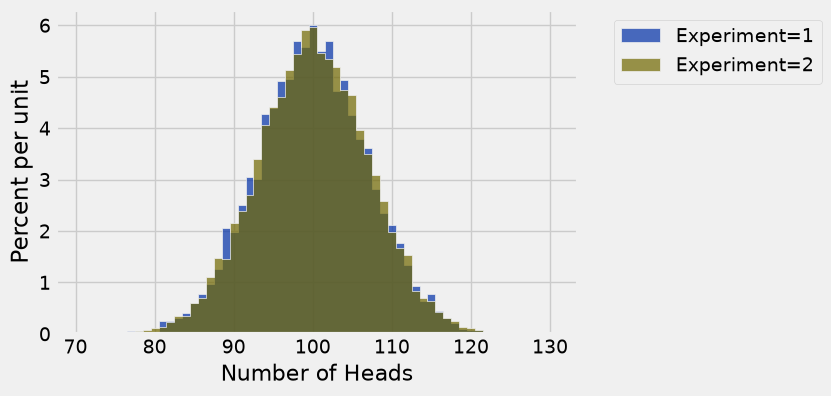

In [54]:
# A large number of simulations provides a good estimate of the
# theoretical distribution of the test statistic under the null hypothesis
num_sims = 10000 # let's try 100, 1000, and 10000
counts_1 = run_test(num_sims, 200)
counts_2 = run_test(num_sims, 200)
t = Table().with_columns(
    'Experiment', [1] * num_sims + [2] * num_sims,
    'Number of Heads', np.append(counts_1, counts_2))
t.hist(1, group='Experiment', bins=np.arange(70.5, 131, 1))

# Titanic

In [24]:
titanic = Table.read_table('data/titanic.csv')
titanic

PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1,0,3,"Braund, Mr. Owen Harris",male,22,1,0,A/5 21171,7.25,nan,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26,0,0,STON/O2. 3101282,7.925,nan,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35,1,0,113803,53.1,C123,S
5,0,3,"Allen, Mr. William Henry",male,35,0,0,373450,8.05,nan,S
6,0,3,"Moran, Mr. James",male,nan,0,0,330877,8.4583,nan,Q
7,0,1,"McCarthy, Mr. Timothy J",male,54,0,0,17463,51.8625,E46,S
8,0,3,"Palsson, Master. Gosta Leonard",male,2,3,1,349909,21.075,nan,S
9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27,0,2,347742,11.1333,nan,S
10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14,1,0,237736,30.0708,nan,C


In [25]:
titanic2 = titanic.select('Sex', 'Survived')
titanic2

Sex,Survived
male,0
female,1
female,1
female,1
male,0
male,0
male,0
male,0
female,1
female,1


In [27]:
titanic2.group('Sex', np.average)

Sex,Survived average
female,0.742038
male,0.188908


In [33]:
titanic2.sample(titanic2.num_rows, with_replacement=False) # you can omit titanic2.num_rows--that's the default

Sex,Survived
female,1
female,1
female,1
male,0
female,1
female,0
female,1
male,0
male,0
male,1


In [43]:
titanic2.with_column(
    'Shuffled Label', titanic2.sample(with_replacement=False).column('Sex')
).group('Shuffled Label', np.average).column(2).item(0)

0.35987261146496813

In [46]:
def one_simulated_rate():
    rate = titanic2.with_column(
        'Shuffled Label', titanic2.sample(with_replacement=False).column('Sex')
    ).group('Shuffled Label', np.average).column(2).item(0)
    return rate

one_simulated_rate()

0.3853503184713376

0.0

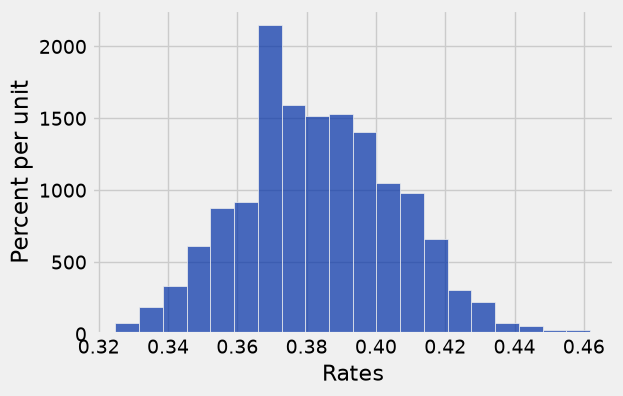

In [48]:
simulations = 1000
simulated_rates = make_array()
for i in np.arange(simulations):
    simulated_rates = np.append(simulated_rates, one_simulated_rate())

Table().with_column('Rates', simulated_rates).hist(0, bins=20)

np.count_nonzero(simulated_rates >= 0.742038) / len(simulated_rates)

# Fish Diet

In [55]:
fish = Table.read_table('data/fish-diet.csv')
fish.sample(10)

Diet,Cancer
Moderate,No
Small,No
Small,No
Moderate,Yes
Large,No
Moderate,No
Small,No
Small,No
Moderate,No
Moderate,No


In [56]:
fish.pivot('Cancer', 'Diet')

Diet,No,Yes
Large,507,42
Moderate,2769,209
Never,110,14
Small,2420,201


In [58]:
fish2 = fish.pivot('Cancer', 'Diet')
fish2.column('Yes') / (fish2.column('Yes') + fish2.column('No'))

array([ 0.07650273,  0.07018133,  0.11290323,  0.07668829])